**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Project Work · **Team 28 · Flying drones · client: Leonardo**

| | |
|---|---|
| **Question (Step 1, Q3)** | Where is it happening? |
| **Approach** | Map the geographical distribution of the sector by analyzing filing offices (IP5) and the countries of applicants and inventors. |
| **Based on** | The counting rules of `tutorial_0/02_step1_general_description.ipynb`: fractional counts for countries, application level for filing offices, last incomplete years excluded. |
| **PATSTAT environment** | TEST while developing, then `ENV = "PROD"` and Run All for the final numbers. |
| **Outputs** | `outputs/step1`: CSV tables and PNG figures for the deck. |


## Why Geography matters for the Drone Sector (Leonardo)

Patent geography provides direct intelligence on the global strategy of drone companies. By looking at where patents are invented versus where they are protected, we can answer key strategic questions for our client:

| Signal | What it measures | Strategic implication for Leonardo |
|---|---|---|
| **Filing offices (IP5)** | Target markets | Shows which countries applicants consider valuable enough to pay for protection. High concentration in certain IP5 offices reveals where the commercial battleground is. |
| **Applicant countries** | Technology ownership | Reveals the nationality of the firms controlling the drone market. |
| **Inventor countries** | R&D locations | Shows where the actual research and development is carried out. |
| **Applicant vs. Inventor gap** | R&D offshoring | A gap between owners and inventors highlights foreign R&D centers, brain drain, or international acquisitions. |

## 1. Set up and Configuration

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

In [2]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                 # "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step1") 

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "Flying Drones"
SECTOR_CPC_PREFIXES = (      # a family is in the sector if any of its CPC symbols starts with one of these
    "B64U", "B64C39/024", "B64C2201"
)
SECTOR_KEYWORDS = (          
    "drone",
    "drones",
    "uav",
    "uavs",
    "unmanned aerial",
    "unmanned aircraft",
    "quadcopter",
    "multicopter",
    "rpas",
    "uas",
)

# ---------------------------------------------------------------- time window
YEAR_MIN, YEAR_MAX = 2000, 2025

# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" earliest priority year (first filing of the invention, anywhere)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only 
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Flying Drones | env: PROD | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


## 2. Sector definition and Query execution

Generating the dataset of drone families by identifying all patents matching our CPC code OR our keywords.

In [3]:
def symbol_prefix_condition(symbol_column, codes):
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

def keyword_condition(terms):
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))

def sector_family_ids(cpc_prefixes=SECTOR_CPC_PREFIXES, keywords=SECTOR_KEYWORDS):
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    
    # 1. CPC Code
    by_cpc = (
        db.query(family_id)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
    )
    if not keywords:
        return by_cpc.distinct()
        
    # 2. keywords
    by_keywords = (
        db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(keywords))
    )
    # 3. Union 
    return by_cpc.union(by_keywords)   

sector_ids = sector_family_ids()
print("ok")

ok


## 3. Creating Scopes

Defining the analysis levels (family vs. application). According to the PW rules, we date families by `earliest_filing_year` and applications by `appln_filing_year`.

In [4]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application
print("ok")

ok


## 4. Counting and Plotting Helpers

Loading the standard PATSTAT functions for fractional counting, aggregations, and data visualization.

In [5]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor').

    Each unit is split among its distinct persons with a known country.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks ('  ')
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Number of units, units via PCT, granted units and mean family size (complete years only)."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)
print("ok")
    

ok


In [6]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes
print("ok")

ok


## 5. Filing offices: the IP5

Where do applicants seek protection? Offices with many sector filings are the markets that applicants consider worth protecting. We look at this at the **application level**, so we can split the sector's applications across offices and the shares sum to exactly 100%.

Share of the sector's applications filed at the IP5: 48.8%


,applications
office,
CN,17.9%
US,11.8%
EP,8.1%
WO,7.9%
JP,6.0%
KR,5.0%
Other,43.3%
Total,100.0%


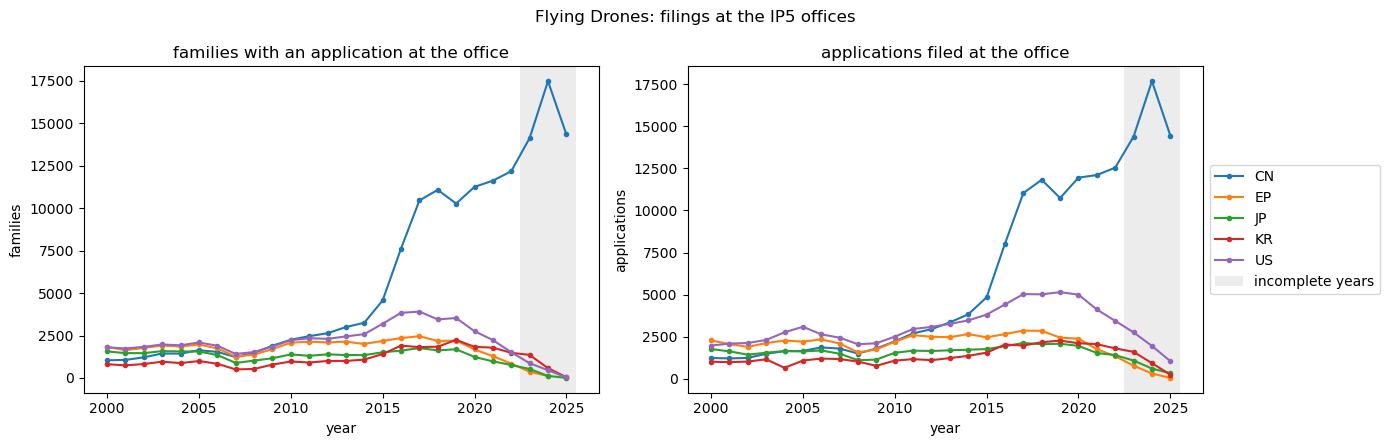

In [7]:
# --- filing offices (IP5) ---
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
display(pct_format(office_shares))

fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family" else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 6. Applicant and inventor countries (fractional counts)

Comparing technology ownership vs. R&D location:
- **Applicant country**: where the owners of the technology are (which firms and countries control it).
- **Inventor country**: where the actual research is carried out.

We use fractional counts: if a family has 2 US applicants and 1 UK applicant, it counts 2/3 for US and 1/3 for UK.

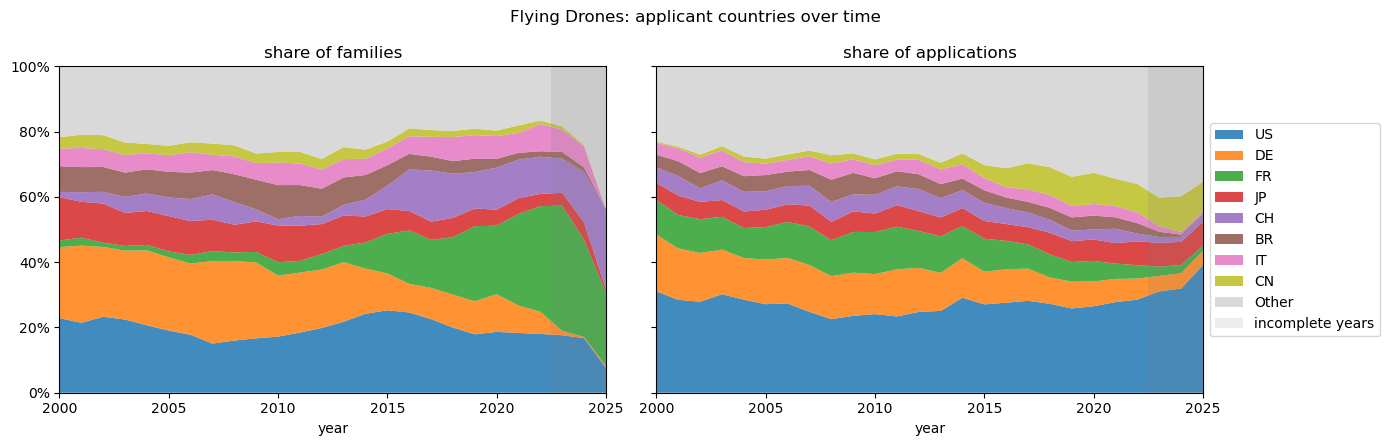

In [8]:

#  Applicant and inventor countries (fractional counts)

countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

# percentuages
country_counts = complete_years(countries).pivot_table(
    index="ctry", columns=["level", "role"], values="n_frac", aggfunc="sum", fill_value=0
)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()

display(pct_format(share_table(country_counts)))

# graph
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()